In [13]:
col_fecha = "Local Date Time"
columnas_originales = {
    "Temperatura exterior (C)": "Temperature Outdoor",
    "Presion atmosferica inhg": "Pressure Relative",
    "Humedad relativa (%)": "Humidity Outdoor",
    "Velocidad viento (km/h)": "Wind Average"}

faltantes = [
    c for c in [col_fecha] + list(columnas_originales.values())
    if c not in df.columns]

if faltantes:raise ValueError(f"Faltan estas columnas: {faltantes}")
df[col_fecha] = pd.to_datetime(df[col_fecha], errors="coerce")
for nombre_es, nombre_original in columnas_originales.items():

    df[nombre_es] = pd.to_numeric(
        df[nombre_original].astype(str).str.extract(
            r"([-+]?\d*\.?\d+)"
        )[0],
        errors="coerce")

columnas_finales = [
    col_fecha,
    "Temperatura exterior (C)",
    "Presion atmosferica inhg",
    "Humedad relativa (%)",
    "Velocidad viento (km/h)"]

df_limpio = df[columnas_finales].copy()
df_limpio = df_limpio.dropna().copy()
df_limpio = df_limpio.sort_values(col_fecha)
df_limpio = df_limpio.reset_index(drop=True)

print("LIMPIEZA COMPLETADA")
print("Registros originales:", len(df))
print("Registros completos:", len(df_limpio))
print("Registros eliminados:", len(df) - len(df_limpio))

print("\nDatos vacíos:")
print(df_limpio.isnull().sum())

display(df_limpio.head())


LIMPIEZA COMPLETADA
Registros originales: 4896
Registros completos: 4677
Registros eliminados: 219

Datos vacíos:
Local Date Time             0
Temperatura exterior (C)    0
Presion atmosferica inhg    0
Humedad relativa (%)        0
Velocidad viento (km/h)     0
dtype: int64


,Local Date Time,Temperatura exterior (C),Presion atmosferica inhg,Humedad relativa (%),Velocidad viento (km/h)
0,2026-10-03 00:05:00,9.5,29.92,90.0,0.0
1,2026-10-03 00:10:00,9.5,29.94,91.0,0.0
2,2026-10-03 00:15:00,9.5,29.93,91.0,0.0
3,2026-10-03 00:20:00,9.5,29.94,91.0,0.0
4,2026-10-03 00:25:00,9.5,29.94,91.0,0.0


Sube el archivo Excel de la Estación 2


Saving Estación_1.xlsx to Estación_1 (2).xlsx


/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


Archivo cargado correctamente.
Hoja utilizada: device_data
Columnas encontradas:
['Local Date Time', 'Device Id', 'Temperature Indoor', 'Temperature Indoor Dew Point', 'Temperature Outdoor', 'Temperature Outdoor At', 'Temperature Outdoor Dew Point', 'Temperature Outdoor Feels Like', 'Humidity Indoor', 'Humidity Outdoor', 'Wind Gust', 'Wind Average', 'Wind Direct', 'Wind Direct Sec', 'Rainfall Rate', 'Rainfall 24h', 'Rainfall Week', 'Rainfall Month', 'Rainfall Total', 'Pressure Absolute', 'Pressure Relative']

LIMPIEZA DE DATOS
Registros originales: 4896
Registros completos: 4677

Valores vacíos:
Local Date Time              0
Temperatura exterior (C)     0
Presion atmosferica (hPa)    0
Humedad relativa (%)         0
Velocidad viento (km/h)      0
dtype: int64

REGISTROS PARA LA GRÁFICA DE PRESIÓN
Desde: 2026-10-17 00:00:00
Hasta: 2026-10-27 23:59:59
Cantidad de registros: 863


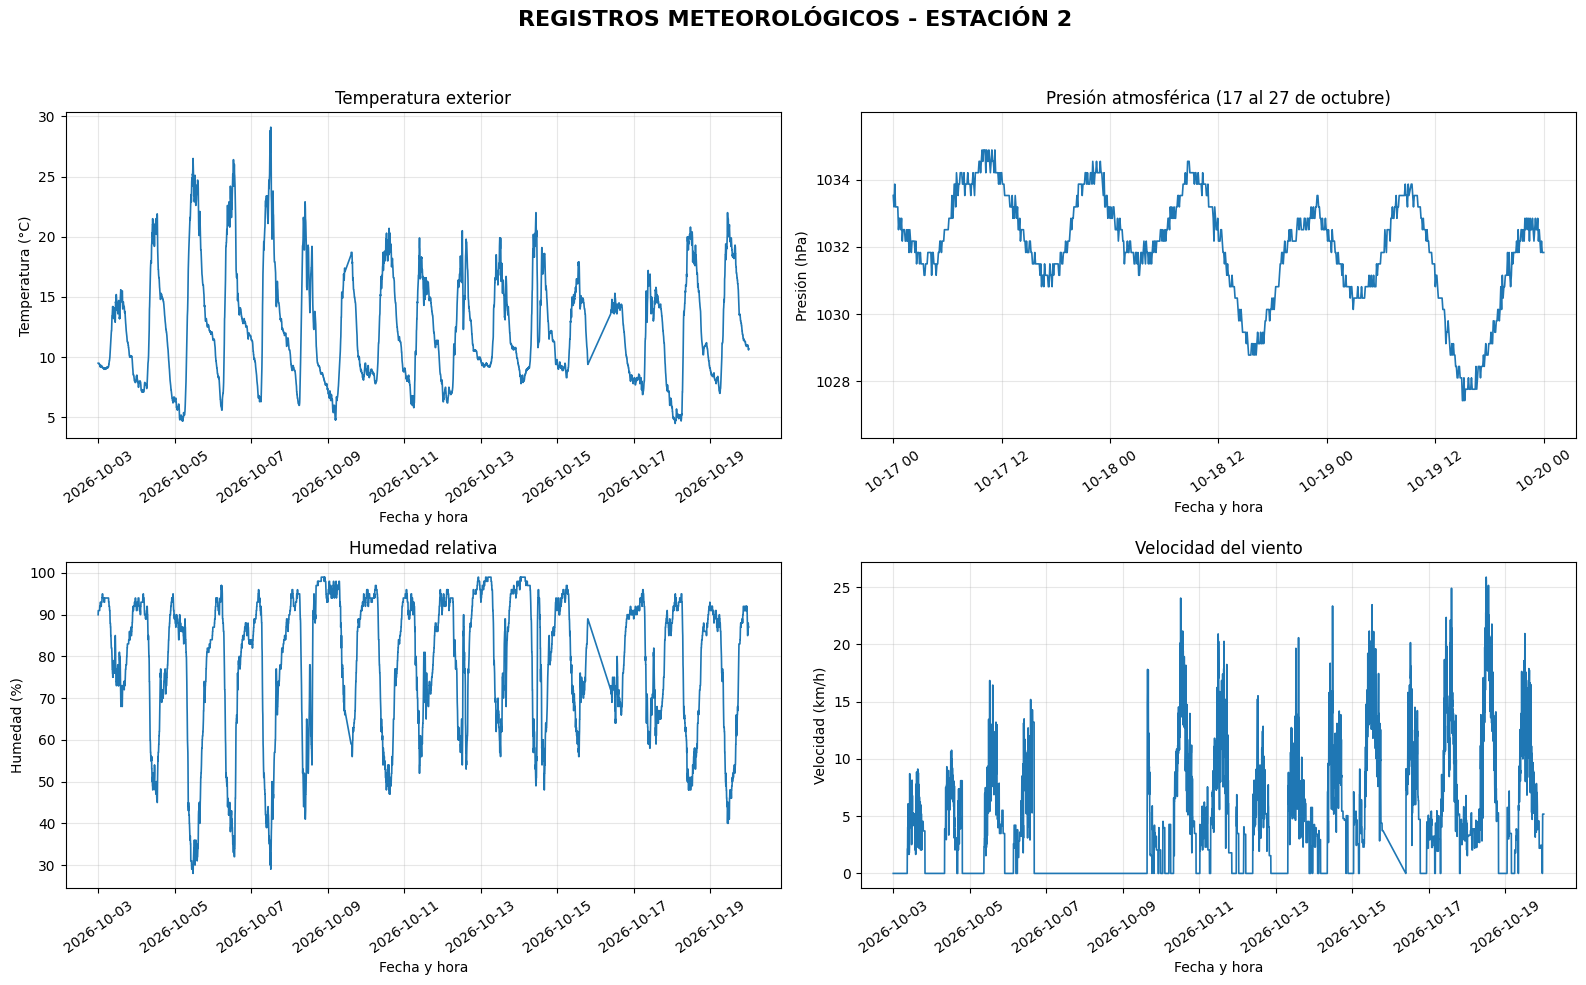


RESUMEN ESTADÍSTICO - ESTACIÓN 2
       Temperatura exterior (C)  Presion atmosferica (hPa)  \
count                   4677.00                    4677.00   
mean                      12.49                    1017.64   
std                        4.64                       7.63   
min                        4.50                    1012.53   
25%                        8.80                    1013.55   
50%                       11.70                    1013.55   
75%                       15.40                    1014.22   
max                       29.10                    1034.88   

       Humedad relativa (%)  Velocidad viento (km/h)  
count               4677.00                  4677.00  
mean                  78.63                     4.34  
std                   16.81                     5.15  
min                   28.00                     0.00  
25%                   68.00                     0.00  
50%                   85.00                     2.95  
75%                   

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

print("Sube el archivo Excel de la Estación 2")
archivos = files.upload()

nombre_archivo = list(archivos.keys())[0]

excel = pd.ExcelFile(nombre_archivo)
hoja = excel.sheet_names[0]

temporal = pd.read_excel(nombre_archivo,sheet_name=hoja,header=None)

fila_encabezado = None

for i in range(len(temporal)):
    valores = temporal.iloc[i].astype(str).str.strip().tolist()

    if "Local Date Time" in valores:
        fila_encabezado = i
        break

if fila_encabezado is None:
    raise ValueError(
        "No se encontró la columna 'Local Date Time'. "
        "Verifica los encabezados del archivo.")

df = pd.read_excel(
    nombre_archivo,
    sheet_name=hoja,
    header=fila_encabezado)

df.columns = df.columns.astype(str).str.strip()

print("Archivo cargado correctamente.")
print("Hoja utilizada:", hoja)
print("Columnas encontradas:")
print(df.columns.tolist())

columnas_necesarias = [
    "Local Date Time",
    "Temperature Outdoor",
    "Pressure Relative",
    "Humidity Outdoor",
    "Wind Average"]

faltantes = [
    columna for columna in columnas_necesarias
    if columna not in df.columns]

if faltantes:
    raise ValueError(
        f"Faltan estas columnas en el Excel: {faltantes}")

df["Local Date Time"] = pd.to_datetime(
    df["Local Date Time"],
    errors="coerce")

def convertir_numero(columna):
    valores = (
        df[columna]
        .astype(str)
        .str.extract(r"([-+]?\d*\.?\d+)")[0])

    return pd.to_numeric(valores, errors="coerce")

df["Temperatura exterior (C)"] = convertir_numero(
    "Temperature Outdoor")
presion_inhg = convertir_numero("Pressure Relative")

df["Presion atmosferica (hPa)"] = (
    presion_inhg * 33.8639)

df["Humedad relativa (%)"] = convertir_numero(
    "Humidity Outdoor")

df["Velocidad viento (km/h)"] = convertir_numero(
    "Wind Average")

columnas_finales = [
    "Local Date Time",
    "Temperatura exterior (C)",
    "Presion atmosferica (hPa)",
    "Humedad relativa (%)",
    "Velocidad viento (km/h)"]

df_limpio = df[columnas_finales].copy()
df_limpio = df_limpio.dropna(
    subset=columnas_finales
)
df_limpio = df_limpio.sort_values(
    by="Local Date Time"
).reset_index(drop=True)

print("\nLIMPIEZA DE DATOS")
print("Registros originales:", len(df))
print("Registros completos:", len(df_limpio))
print("\nValores vacíos:")
print(df_limpio.isnull().sum())

if df_limpio.empty:
    raise ValueError(
        "No quedaron registros completos. "
        "Revisa las fechas y los valores del archivo.")

inicio = pd.Timestamp("2026-10-17 00:00:00")
fin = pd.Timestamp("2026-10-28 00:00:00")

df_presion = df_limpio[
    (df_limpio["Local Date Time"] >= inicio) &
    (df_limpio["Local Date Time"] < fin)
].copy()

print("\nREGISTROS PARA LA GRÁFICA DE PRESIÓN")
print("Desde:", inicio)
print("Hasta:", "2026-10-27 23:59:59")
print("Cantidad de registros:", len(df_presion))

if df_presion.empty:
    print("ADVERTENCIA: No hay registros de presión "
        "entre el 17 y el 27 de octubre de 2026.")

fig, ejes = plt.subplots(
    2, 2,
    figsize=(16, 10))

fig.suptitle(
    "REGISTROS METEOROLÓGICOS - ESTACIÓN 2",
    fontsize=16,
    fontweight="bold")

ejes[0, 0].plot(
    df_limpio["Local Date Time"],
    df_limpio["Temperatura exterior (C)"],
    linewidth=1.2)

ejes[0, 0].set_title(
    "Temperatura exterior")

ejes[0, 0].set_xlabel("Fecha y hora")
ejes[0, 0].set_ylabel("Temperatura (°C)")
ejes[0, 0].grid(True, alpha=0.3)

if not df_presion.empty:

    ejes[0, 1].plot(
        df_presion["Local Date Time"],
        df_presion["Presion atmosferica (hPa)"],
        linewidth=1.2)

    ejes[0, 1].set_title(
        "Presión atmosférica (17 al 27 de octubre)")
    minimo = df_presion["Presion atmosferica (hPa)"].min()
    maximo = df_presion["Presion atmosferica (hPa)"].max()

    rango = maximo - minimo
    if rango == 0:
        margen = max(abs(minimo) * 0.01, 1)
    else:
        margen = rango * 0.15
    ejes[0, 1].set_ylim(
        minimo - margen,
        maximo + margen)
else:
    ejes[0, 1].text(
        0.5, 0.5,
        "No hay registros en el periodo seleccionado",
        ha="center",
        va="center",
        transform=ejes[0, 1].transAxes)

    ejes[0, 1].set_title(
        "Presión atmosférica (17 al 27 de octubre)")

ejes[0, 1].set_xlabel("Fecha y hora")
ejes[0, 1].set_ylabel("Presión (hPa)")
ejes[0, 1].grid(True, alpha=0.3)


ejes[1, 0].plot(
    df_limpio["Local Date Time"],
    df_limpio["Humedad relativa (%)"],
    linewidth=1.2)

ejes[1, 0].set_title(
    "Humedad relativa")

ejes[1, 0].set_xlabel("Fecha y hora")
ejes[1, 0].set_ylabel("Humedad (%)")
ejes[1, 0].grid(True, alpha=0.3)

ejes[1, 1].plot(
    df_limpio["Local Date Time"],
    df_limpio["Velocidad viento (km/h)"],
    linewidth=1.2)

ejes[1, 1].set_title(
    "Velocidad del viento")

ejes[1, 1].set_xlabel("Fecha y hora")
ejes[1, 1].set_ylabel("Velocidad (km/h)")
ejes[1, 1].grid(True, alpha=0.3)

for eje in ejes.flat:
    eje.tick_params(axis="x", rotation=35)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

print("\nRESUMEN ESTADÍSTICO - ESTACIÓN 2")

print(
    df_limpio[
        [
            "Temperatura exterior (C)",
            "Presion atmosferica (hPa)",
            "Humedad relativa (%)",
            "Velocidad viento (km/h)"
        ]
    ].describe().round(2))


ENTRENAMIENTO DE LOS MODELOS


Sube el archivo original de la Estación 2


Saving Estación_1.xlsx to Estación_1 (4).xlsx


/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")



Datos cargados correctamente
Cantidad de registros: 4896
Columnas: ['Local Date Time', 'Device Id', 'Temperature Indoor', 'Temperature Indoor Dew Point', 'Temperature Outdoor', 'Temperature Outdoor At', 'Temperature Outdoor Dew Point', 'Temperature Outdoor Feels Like', 'Humidity Indoor', 'Humidity Outdoor', 'Wind Gust', 'Wind Average', 'Wind Direct', 'Wind Direct Sec', 'Rainfall Rate', 'Rainfall 24h', 'Rainfall Week', 'Rainfall Month', 'Rainfall Total', 'Pressure Absolute', 'Pressure Relative']

Registros completos: 4677

ENTRENANDO SVR PARA: Temperatura exterior (C)

Mejores parámetros:
{'svr__C': 10, 'svr__epsilon': 0.01, 'svr__gamma': 0.01, 'svr__kernel': 'rbf'}

RESULTADOS:
R²: 0.8642
MAE: 1.3323
MSE: 2.7820
RMSE: 1.6679
Ajuste estimado: 88.86%

ENTRENANDO SVR PARA: Presion atmosferica (hPa)

Mejores parámetros:
{'svr__C': 100, 'svr__epsilon': 0.01, 'svr__gamma': 0.01, 'svr__kernel': 'rbf'}

RESULTADOS:
R²: 0.7496
MAE: 0.6337
MSE: 0.6381
RMSE: 0.7988
Ajuste estimado: 99.94%

ENTRE

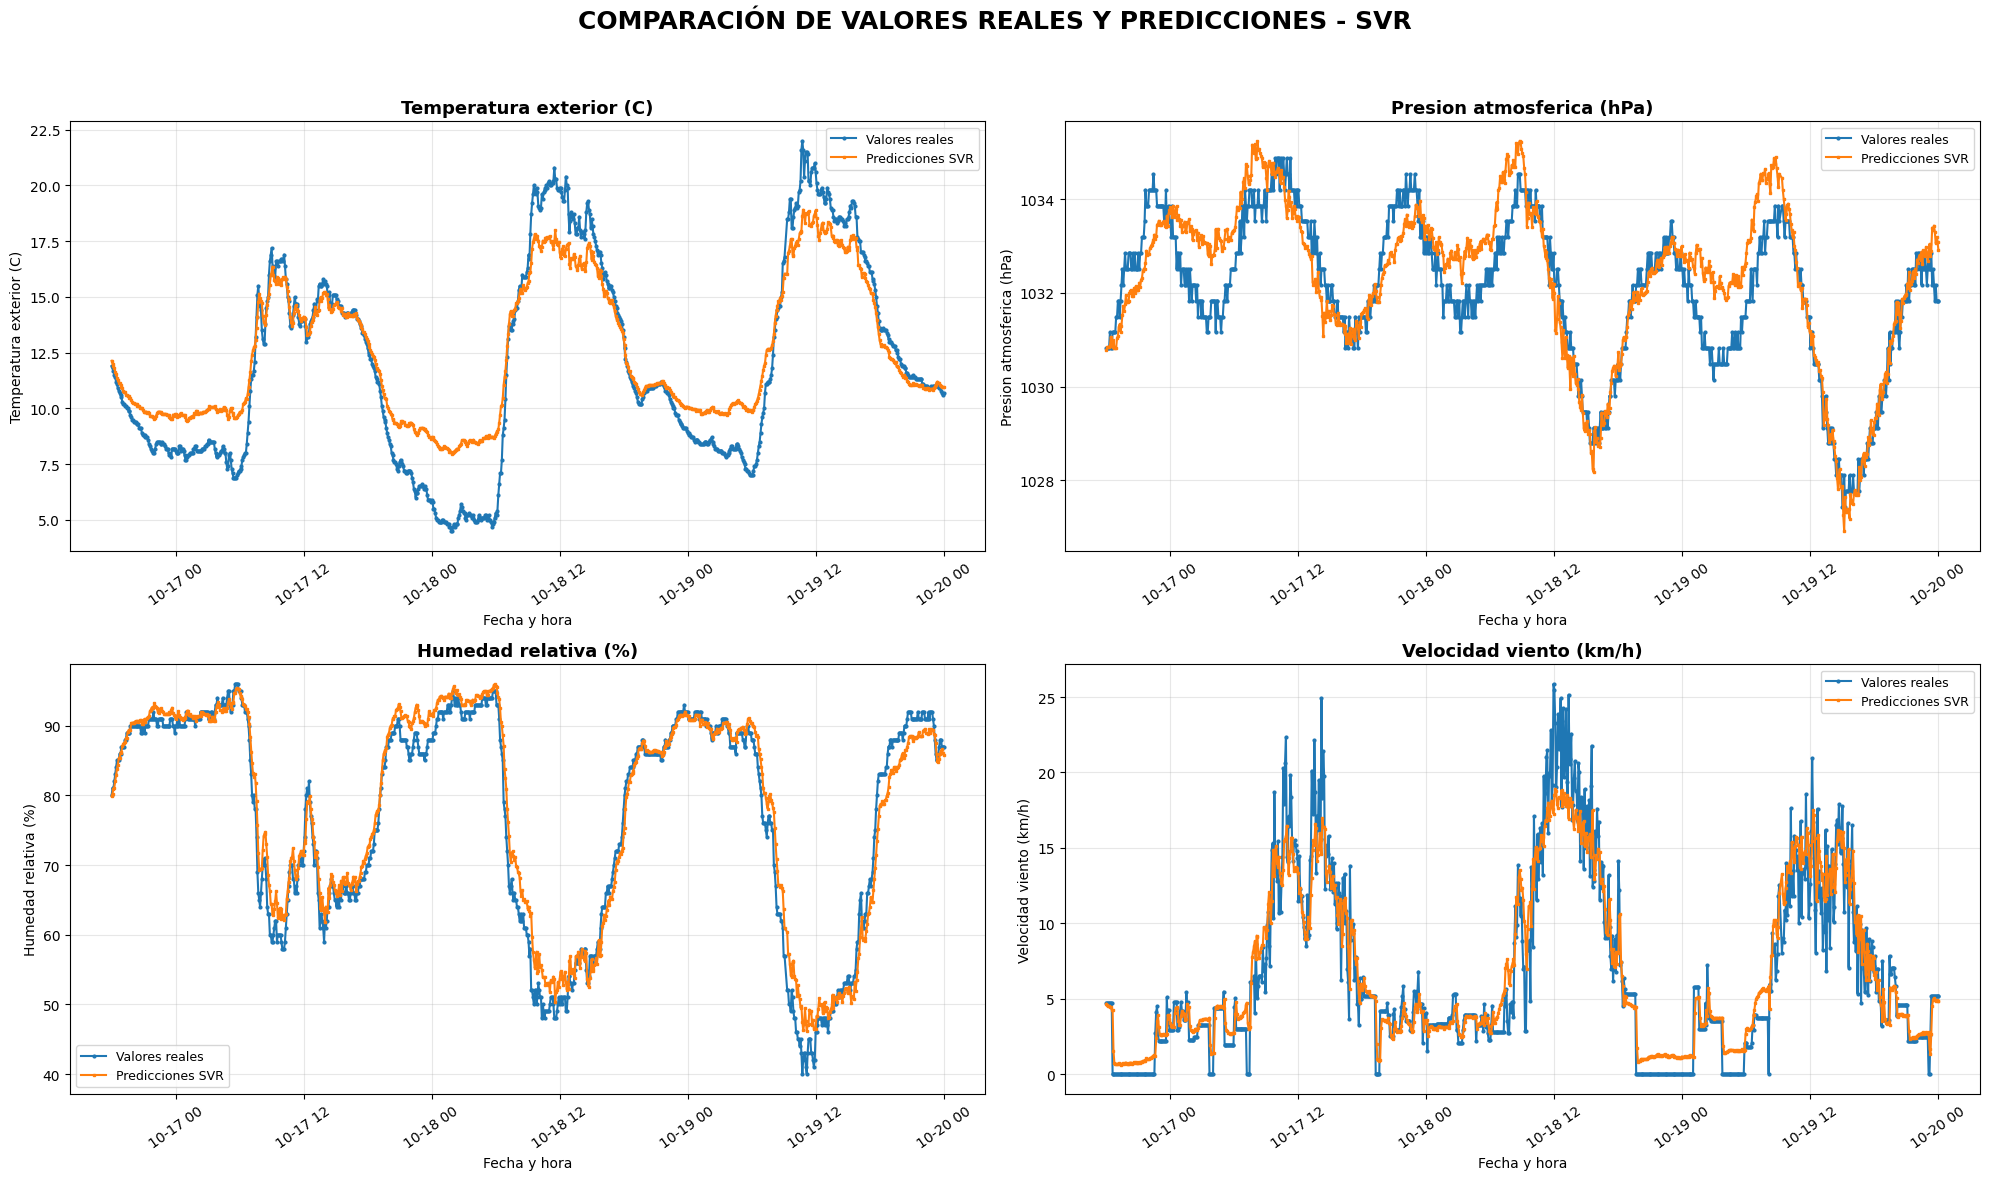


RESUMEN GENERAL DEL MODELO SVR - ESTACIÓN 2


,Variable,R2,MAE,MSE,RMSE,Ajuste estimado (%)
0,Temperatura exterior (C),0.8642,1.3323,2.7820,1.6679,88.8611
1,Presion atmosferica (hPa),0.7496,0.6337,0.6381,0.7988,99.9386
2,Humedad relativa (%),0.9665,2.2223,8.2205,2.8671,97.1163
3,Velocidad viento (km/h),0.8765,1.4866,4.4003,2.0977,77.6784



ENTRENAMIENTO SVR FINALIZADO CORRECTAMENTE

RESUMEN DE RESULTADOS:


,Variable,R2,MAE,MSE,RMSE,Ajuste estimado (%)
0,Temperatura exterior (C),0.8642,1.3323,2.7820,1.6679,88.8611
1,Presion atmosferica (hPa),0.7496,0.6337,0.6381,0.7988,99.9386
2,Humedad relativa (%),0.9665,2.2223,8.2205,2.8671,97.1163
3,Velocidad viento (km/h),0.8765,1.4866,4.4003,2.0977,77.6784


In [17]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error)

print("Sube el archivo original de la Estación 2")
archivos = files.upload()
nombre_archivo = list(archivos.keys())[0]

excel = pd.ExcelFile(nombre_archivo)
hoja = excel.sheet_names[0]

temporal = pd.read_excel(
    nombre_archivo,
    sheet_name=hoja,
    header=None)

fila_encabezado = None

for i in range(len(temporal)):
    valores = temporal.iloc[i].astype(str).str.strip().tolist()

    if "Local Date Time" in valores:
        fila_encabezado = i
        break

if fila_encabezado is None:
    raise ValueError("No se encontró la fila de encabezados.")

df = pd.read_excel(
    nombre_archivo,
    sheet_name=hoja,
    header=fila_encabezado)

df.columns = df.columns.astype(str).str.strip()

print("\nDatos cargados correctamente")
print("Cantidad de registros:", len(df))
print("Columnas:", df.columns.tolist())

columnas_originales = [
    "Local Date Time",
    "Temperature Outdoor",
    "Pressure Relative",
    "Humidity Outdoor",
    "Wind Average"]

faltantes = [ c for c in columnas_originales
    if c not in df.columns]

if faltantes:
    raise ValueError(f"Faltan columnas originales: {faltantes}")

df["Local Date Time"] = pd.to_datetime(
    df["Local Date Time"],
    errors="coerce")

def convertir_numero(columna):
    valores = df[columna].astype(str).str.extract(
        r"([-+]?\d*\.?\d+)")[0]

    return pd.to_numeric(valores, errors="coerce")

df["Temperatura exterior (C)"] = convertir_numero(
    "Temperature Outdoor")

# Conversión de inHg a hPa
df["Presion atmosferica (hPa)"] = (
    convertir_numero("Pressure Relative") * 33.8639)

df["Humedad relativa (%)"] = convertir_numero(
    "Humidity Outdoor")

df["Velocidad viento (km/h)"] = convertir_numero(
    "Wind Average")

variables = ["Temperatura exterior (C)",
    "Presion atmosferica (hPa)",
    "Humedad relativa (%)",
    "Velocidad viento (km/h)"]

df = df.dropna(
    subset=["Local Date Time"] + variables).sort_values(
    "Local Date Time").reset_index(drop=True)

print("\nRegistros completos:", len(df))

if len(df) < 20:
    raise ValueError("Hay muy pocos registros para entrenar.")

df["hora"] = (
    df["Local Date Time"].dt.hour
    + df["Local Date Time"].dt.minute / 60)

df["dia"] = df["Local Date Time"].dt.dayofyear

df["hora_sin"] = np.sin(2 * np.pi * df["hora"] / 24)
df["hora_cos"] = np.cos(2 * np.pi * df["hora"] / 24)

df["dia_sin"] = np.sin(2 * np.pi * df["dia"] / 365.25)
df["dia_cos"] = np.cos(2 * np.pi * df["dia"] / 365.25)

for col in variables:
    df[col + "_lag1"] = df[col].shift(1)
    df[col + "_lag2"] = df[col].shift(2)

df = df.dropna().reset_index(drop=True)

caracteristicas = [
    "Temperatura exterior (C)_lag1",
    "Temperatura exterior (C)_lag2",
    "Presion atmosferica (hPa)_lag1",
    "Presion atmosferica (hPa)_lag2",
    "Humedad relativa (%)_lag1",
    "Humedad relativa (%)_lag2",
    "Velocidad viento (km/h)_lag1",
    "Velocidad viento (km/h)_lag2",
    "hora_sin",
    "hora_cos",
    "dia_sin",
    "dia_cos"]

parametros = {
    "svr__C": [1, 10, 100],
    "svr__epsilon": [0.01, 0.1, 0.2],
    "svr__gamma": ["scale", 0.01, 0.1],
    "svr__kernel": ["rbf"]}

resultados = []
predicciones = {}
modelos_entrenados = {}

fig, ejes = plt.subplots(
    2, 2,
    figsize=(20, 12))

ejes = ejes.flatten()

for posicion, variable in enumerate(variables):

    print("\n" + "=" * 60)
    print("ENTRENANDO SVR PARA:", variable)
    print("=" * 60)

    X = df[caracteristicas]
    y = df[variable]

    corte = int(len(df) * 0.80)

    X_train = X.iloc[:corte]
    X_test = X.iloc[corte:]

    y_train = y.iloc[:corte]
    y_test = y.iloc[corte:]

    pipeline = Pipeline([
        ("escalador", StandardScaler()),
        ("svr", SVR())])

    busqueda = GridSearchCV(
        estimator=pipeline,
        param_grid=parametros,
        scoring="neg_mean_absolute_error",
        cv=3,
        n_jobs=-1)

    busqueda.fit(X_train, y_train)

    mejor_modelo = busqueda.best_estimator_

    y_pred = mejor_modelo.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)

    media_real = np.mean(np.abs(y_test))

    if media_real > 0:
        ajuste = max(
            0,
            100 * (1 - mae / media_real))
    else:
        ajuste = np.nan

    resultados.append({
        "Variable": variable,
        "R2": r2,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "Ajuste estimado (%)": ajuste})

    modelos_entrenados[variable] = mejor_modelo

    fechas_test = df["Local Date Time"].iloc[corte:]

    predicciones[variable] = pd.DataFrame({
        "Fecha y hora": fechas_test.values,
        "Valor real": y_test.values,
        "Prediccion SVR": y_pred})

    print("\nMejores parámetros:")
    print(busqueda.best_params_)

    print("\nRESULTADOS:")
    print(f"R²: {r2:.4f}")
    print(f"MAE: {mae:.4f}")
    print(f"MSE: {mse:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"Ajuste estimado: {ajuste:.2f}%")

    ax = ejes[posicion]

    ax.plot(
        fechas_test,
        y_test.values,
        label="Valores reales",
        marker="o",
        markersize=2,
        linewidth=1.5)

    ax.plot(
        fechas_test,
        y_pred,
        label="Predicciones SVR",
        marker="s",
        markersize=2,
        linewidth=1.5)

    ax.set_title(
        variable,
        fontsize=13,
        fontweight="bold")

    ax.set_xlabel("Fecha y hora", fontsize=10)
    ax.set_ylabel(variable, fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis="x", rotation=35)

fig.suptitle(
    "COMPARACIÓN DE VALORES REALES Y PREDICCIONES - SVR",
    fontsize=18,
    fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

tabla_resultados = pd.DataFrame(resultados)

print("\n" + "=" * 70)
print("RESUMEN GENERAL DEL MODELO SVR - ESTACIÓN 2")
print("=" * 70)

display(tabla_resultados.round(4))

print("\nENTRENAMIENTO SVR FINALIZADO CORRECTAMENTE")

print("\nRESUMEN DE RESULTADOS:")
display(tabla_resultados.round(4))


Registros para entrenamiento: 3738
Registros para prueba: 935

Entrenando Random Forest para: Temperatura exterior (C)
R²: 0.9912
MAE: 0.2529
MSE: 0.1806
RMSE: 0.425
Ajuste estimado: 97.89 %

Entrenando Random Forest para: Presion atmosferica (hPa)
R²: 0.7649
MAE: 0.5659
MSE: 0.5991
RMSE: 0.774
Ajuste estimado: 99.95 %

Entrenando Random Forest para: Humedad relativa (%)
R²: 0.9182
MAE: 2.6
MSE: 20.056
RMSE: 4.4784
Ajuste estimado: 96.63 %

Entrenando Random Forest para: Velocidad viento (km/h)
R²: 0.8119
MAE: 1.8344
MSE: 6.6989
RMSE: 2.5882
Ajuste estimado: 72.46 %

RESULTADOS GENERALES - RANDOM FOREST


,Variable,R2,MAE,MSE,RMSE,Ajuste estimado (%)
0,Temperatura exterior (C),0.9912,0.2529,0.1806,0.4250,97.8853
1,Presion atmosferica (hPa),0.7649,0.5659,0.5991,0.7740,99.9452
2,Humedad relativa (%),0.9182,2.6000,20.0560,4.4784,96.6262
3,Velocidad viento (km/h),0.8119,1.8344,6.6989,2.5882,72.4553


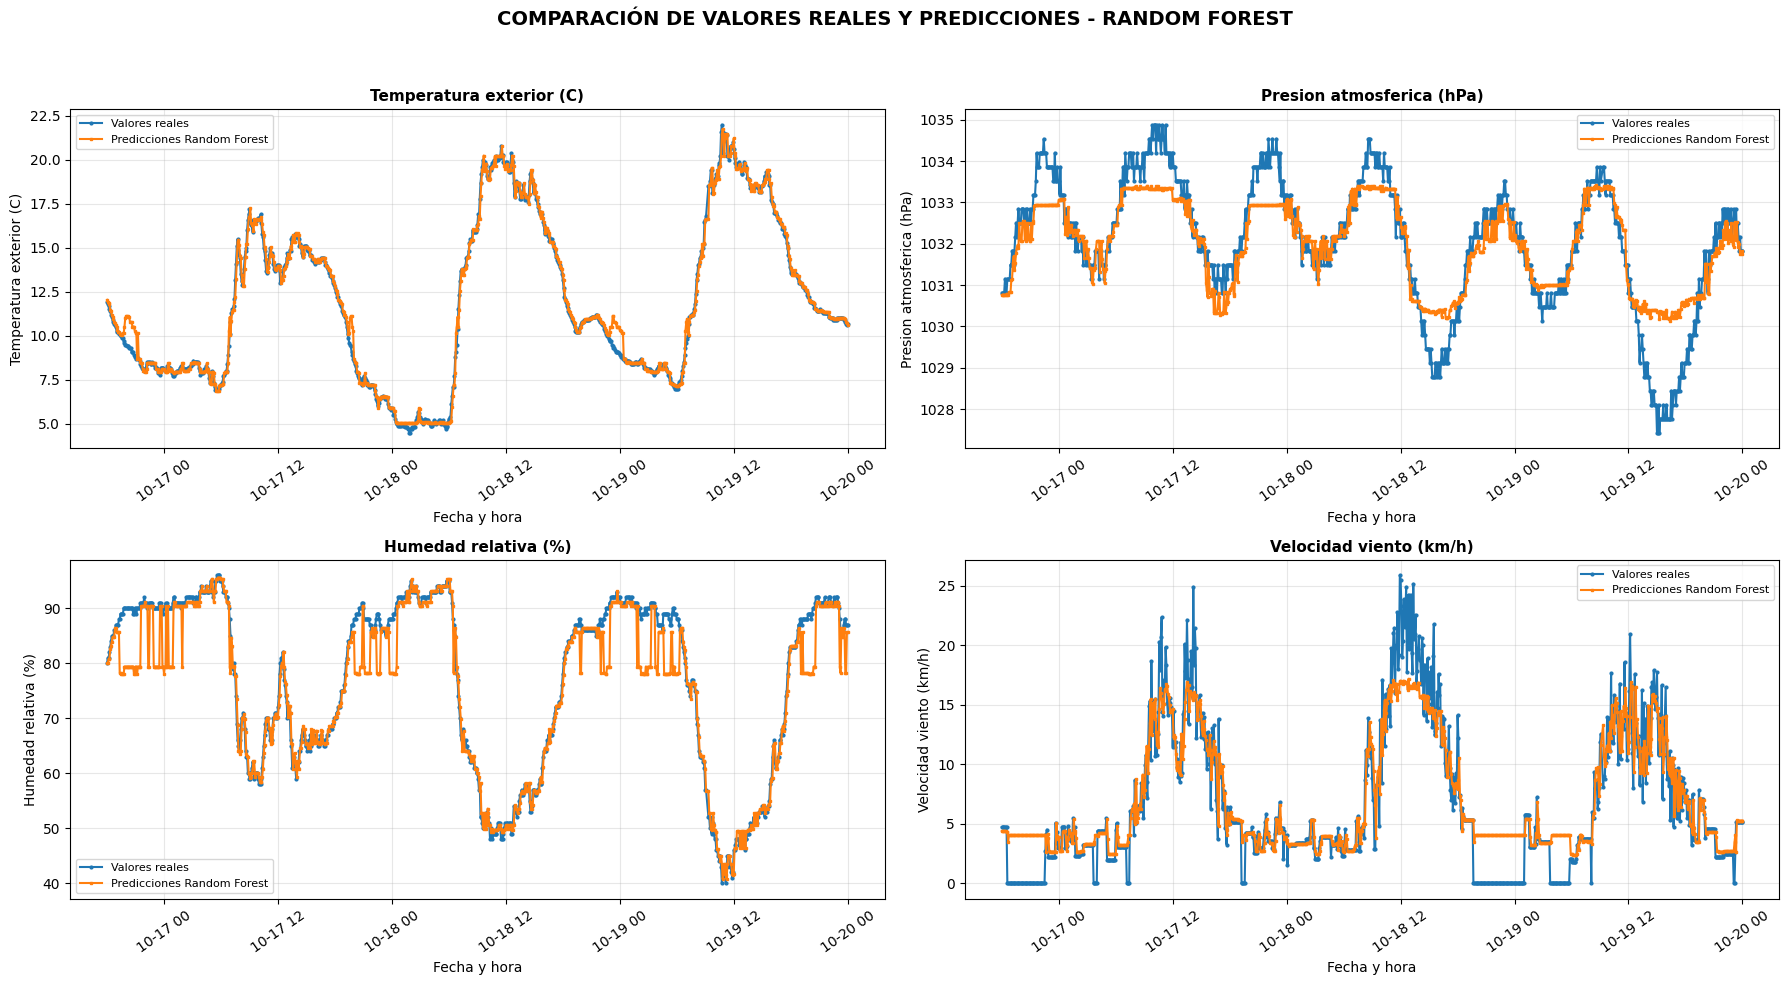


ENTRENAMIENTO RANDOM FOREST FINALIZADO


In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error)

variables = [
    "Temperatura exterior (C)",
    "Presion atmosferica (hPa)",
    "Humedad relativa (%)",
    "Velocidad viento (km/h)"]
datos = df.copy()

datos["Fecha y hora"] = pd.to_datetime(
    datos["Local Date Time"],
    errors="coerce")

datos = datos.dropna(subset=["Fecha y hora"] + variables)
datos = datos.sort_values("Fecha y hora").reset_index(drop=True)

datos["hora"] = datos["Fecha y hora"].dt.hour
datos["dia"] = datos["Fecha y hora"].dt.dayofyear

datos["hora_sin"] = np.sin(2 * np.pi * datos["hora"] / 24)
datos["hora_cos"] = np.cos(2 * np.pi * datos["hora"] / 24)

datos["dia_sin"] = np.sin(2 * np.pi * datos["dia"] / 365)
datos["dia_cos"] = np.cos(2 * np.pi * datos["dia"] / 365)

for variable in variables:
    datos[variable + "_lag1"] = datos[variable].shift(1)
    datos[variable + "_lag2"] = datos[variable].shift(2)

datos = datos.dropna().reset_index(drop=True)

caracteristicas = []

for variable in variables:
    caracteristicas.append(variable + "_lag1")
    caracteristicas.append(variable + "_lag2")

caracteristicas += [
    "hora_sin",
    "hora_cos",
    "dia_sin",
    "dia_cos"]

X = datos[caracteristicas]
corte = int(len(datos) * 0.80)

X_train = X.iloc[:corte]
X_test = X.iloc[corte:]

fechas_test = datos["Fecha y hora"].iloc[corte:]

print("Registros para entrenamiento:", len(X_train))
print("Registros para prueba:", len(X_test))

resultados = []
modelos_entrenados = {}
predicciones = {}

for variable in variables:

    print("\nEntrenando Random Forest para:", variable)

    y = datos[variable]

    y_train = y.iloc[:corte]
    y_test = y.iloc[corte:]

    modelo = RandomForestRegressor(
        n_estimators=100,
        max_leaf_nodes=40,
        random_state=42,
        n_jobs=-1)

    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    promedio_real = np.mean(np.abs(y_test))

    if promedio_real != 0:
        ajuste = max(0, 100 * (1 - mae / promedio_real))
    else:
        ajuste = 0

    resultados.append({
        "Variable": variable,
        "R2": r2,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "Ajuste estimado (%)": ajuste})

    modelos_entrenados[variable] = modelo
    predicciones[variable] = y_pred

    print("R²:", round(r2, 4))
    print("MAE:", round(mae, 4))
    print("MSE:", round(mse, 4))
    print("RMSE:", round(rmse, 4))
    print("Ajuste estimado:", round(ajuste, 2), "%")

tabla_resultados = pd.DataFrame(resultados)

print("\nRESULTADOS GENERALES - RANDOM FOREST")
display(tabla_resultados.round(4))

fig, ejes = plt.subplots(2, 2, figsize=(18, 10))
ejes = ejes.flatten()

for posicion, variable in enumerate(variables):

    ax = ejes[posicion]

    y_test = datos[variable].iloc[corte:]
    y_pred = predicciones[variable]

    ax.plot(fechas_test,
        y_test.values,
        label="Valores reales",
        marker="o",
        markersize=2,
        linewidth=1.5)

    ax.plot(fechas_test,
        y_pred,
        label="Predicciones Random Forest",
        marker="s",
        markersize=2,
        linewidth=1.5)

    ax.set_title(variable, fontsize=11, fontweight="bold")
    ax.set_xlabel("Fecha y hora")
    ax.set_ylabel(variable)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis="x", rotation=35)

fig.suptitle(
    "COMPARACIÓN DE VALORES REALES Y PREDICCIONES - RANDOM FOREST",
    fontsize=14,
    fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

print("\nENTRENAMIENTO RANDOM FOREST FINALIZADO")


Registros para entrenamiento: 3738
Registros para prueba: 935

Entrenando Gradient Boosting para: Temperatura exterior (C)
R²: 0.9246
MAE: 1.0019
MSE: 1.5454
RMSE: 1.2431
Ajuste estimado: 91.62 %

Entrenando Gradient Boosting para: Presion atmosferica (hPa)
R²: 0.575
MAE: 0.8299
MSE: 1.0832
RMSE: 1.0408
Ajuste estimado: 99.92 %

Entrenando Gradient Boosting para: Humedad relativa (%)
R²: 0.876
MAE: 4.4014
MSE: 30.4117
RMSE: 5.5147
Ajuste estimado: 94.29 %

Entrenando Gradient Boosting para: Velocidad viento (km/h)
R²: 0.8473
MAE: 1.7349
MSE: 5.441
RMSE: 2.3326
Ajuste estimado: 73.95 %

RESULTADOS GENERALES - GRADIENT BOOSTING


,Variable,R2,MAE,MSE,RMSE,Ajuste estimado (%)
0,Temperatura exterior (C),0.9246,1.0019,1.5454,1.2431,91.6236
1,Presion atmosferica (hPa),0.5750,0.8299,1.0832,1.0408,99.9196
2,Humedad relativa (%),0.8760,4.4014,30.4117,5.5147,94.2887
3,Velocidad viento (km/h),0.8473,1.7349,5.4410,2.3326,73.9505


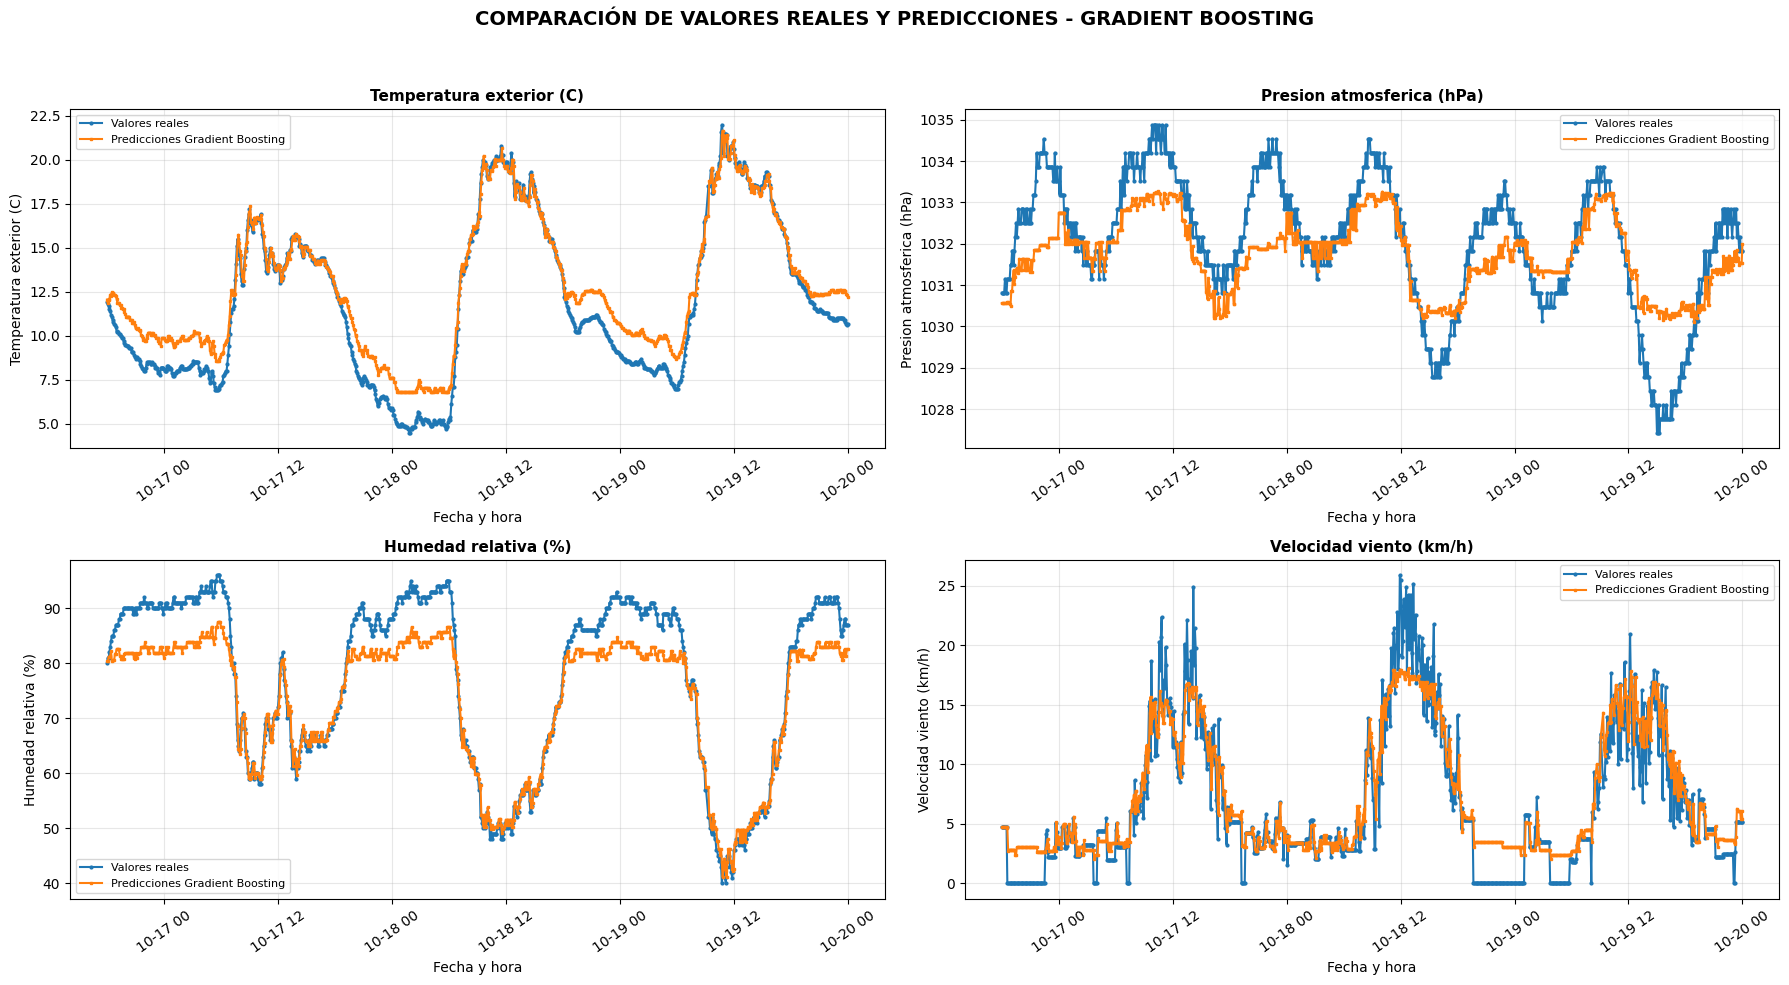


ENTRENAMIENTO GRADIENT BOOSTING FINALIZADO


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error)

variables = [
    "Temperatura exterior (C)",
    "Presion atmosferica (hPa)",
    "Humedad relativa (%)",
    "Velocidad viento (km/h)"]

datos = df.copy()
datos["Fecha y hora"] = pd.to_datetime(datos["Local Date Time"],errors="coerce")

datos = datos.dropna(subset=["Fecha y hora"] + variables)
datos = datos.sort_values("Fecha y hora").reset_index(drop=True)

datos["hora"] = datos["Fecha y hora"].dt.hour
datos["dia"] = datos["Fecha y hora"].dt.dayofyear

datos["hora_sin"] = np.sin(2 * np.pi * datos["hora"] / 24)
datos["hora_cos"] = np.cos(2 * np.pi * datos["hora"] / 24)

datos["dia_sin"] = np.sin(2 * np.pi * datos["dia"] / 365)
datos["dia_cos"] = np.cos(2 * np.pi * datos["dia"] / 365)

for variable in variables:
    datos[variable + "_lag1"] = datos[variable].shift(1)
    datos[variable + "_lag2"] = datos[variable].shift(2)

datos = datos.dropna().reset_index(drop=True)

caracteristicas = []

for variable in variables:
    caracteristicas.append(variable + "_lag1")
    caracteristicas.append(variable + "_lag2")

caracteristicas += [
    "hora_sin",
    "hora_cos",
    "dia_sin",
    "dia_cos"]

X = datos[caracteristicas]
corte = int(len(datos) * 0.80)

X_train = X.iloc[:corte]
X_test = X.iloc[corte:]

fechas_test = datos["Fecha y hora"].iloc[corte:]

print("Registros para entrenamiento:", len(X_train))
print("Registros para prueba:", len(X_test))

resultados = []
modelos_entrenados = {}
predicciones = {}

for variable in variables:

    print("\nEntrenando Gradient Boosting para:", variable)

    y = datos[variable]

    y_train = y.iloc[:corte]
    y_test = y.iloc[corte:]

    modelo = GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        min_samples_split=2,
        min_samples_leaf=1,
        loss="squared_error",
        random_state=42 )

    modelo.fit(X_train, y_train)

    y_pred = modelo.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)

    promedio_real = np.mean(np.abs(y_test))

    if promedio_real != 0:
        ajuste = max(0, 100 * (1 - mae / promedio_real))
    else:
        ajuste = 0

    resultados.append({
        "Variable": variable,
        "R2": r2,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "Ajuste estimado (%)": ajuste})

    modelos_entrenados[variable] = modelo
    predicciones[variable] = y_pred

    print("R²:", round(r2, 4))
    print("MAE:", round(mae, 4))
    print("MSE:", round(mse, 4))
    print("RMSE:", round(rmse, 4))
    print("Ajuste estimado:", round(ajuste, 2), "%")

tabla_resultados = pd.DataFrame(resultados)

print("\nRESULTADOS GENERALES - GRADIENT BOOSTING")
display(tabla_resultados.round(4))

fig, ejes = plt.subplots(2, 2, figsize=(18, 10))
ejes = ejes.flatten()

for posicion, variable in enumerate(variables):

    ax = ejes[posicion]

    y_test = datos[variable].iloc[corte:]
    y_pred = predicciones[variable]

    ax.plot(
        fechas_test,
        y_test.values,
        label="Valores reales",
        marker="o",
        markersize=2,
        linewidth=1.5)

    ax.plot(
        fechas_test,
        y_pred,
        label="Predicciones Gradient Boosting",
        marker="s",
        markersize=2,
        linewidth=1.5)

    ax.set_title(variable, fontsize=11, fontweight="bold")
    ax.set_xlabel("Fecha y hora")
    ax.set_ylabel(variable)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis="x", rotation=35)

fig.suptitle(
    "COMPARACIÓN DE VALORES REALES Y PREDICCIONES - GRADIENT BOOSTING",
    fontsize=14,
    fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

print("\nENTRENAMIENTO GRADIENT BOOSTING FINALIZADO")


Registros para entrenamiento: 3738
Registros para prueba: 935

Entrenando Regresión Lineal para: Temperatura exterior (C)
R²: 0.9972
MAE: 0.155
MSE: 0.0579
RMSE: 0.2406
Ajuste estimado: 98.7 %

Entrenando Regresión Lineal para: Presion atmosferica (hPa)
R²: 0.9674
MAE: 0.2284
MSE: 0.0831
RMSE: 0.2882
Ajuste estimado: 99.98 %

Entrenando Regresión Lineal para: Humedad relativa (%)
R²: 0.996
MAE: 0.7057
MSE: 0.9895
RMSE: 0.9947
Ajuste estimado: 99.08 %

Entrenando Regresión Lineal para: Velocidad viento (km/h)
R²: 0.8857
MAE: 1.4274
MSE: 4.0724
RMSE: 2.018
Ajuste estimado: 78.57 %

RESULTADOS GENERALES - REGRESIÓN LINEAL


,Variable,R2,MAE,MSE,RMSE,Ajuste estimado (%)
0,Temperatura exterior (C),0.9972,0.1550,0.0579,0.2406,98.7045
1,Presion atmosferica (hPa),0.9674,0.2284,0.0831,0.2882,99.9779
2,Humedad relativa (%),0.9960,0.7057,0.9895,0.9947,99.0843
3,Velocidad viento (km/h),0.8857,1.4274,4.0724,2.0180,78.5663


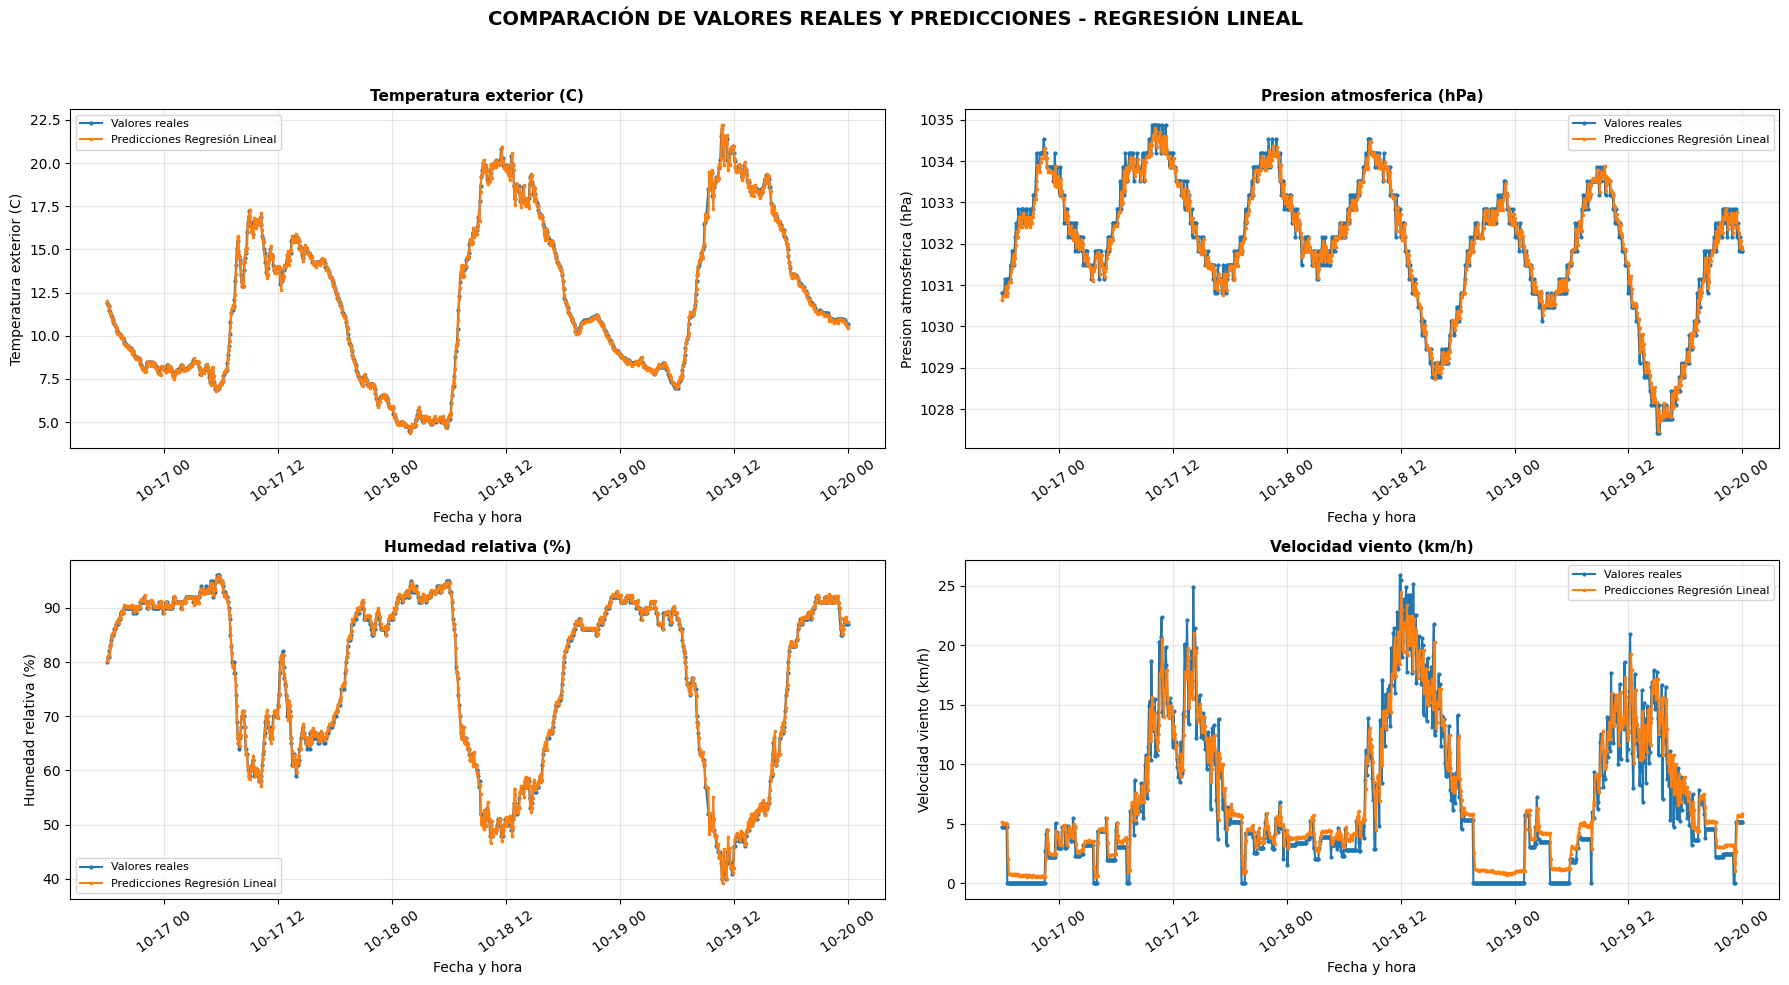


ENTRENAMIENTO REGRESIÓN LINEAL FINALIZADO


In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error)

variables = [
    "Temperatura exterior (C)",
    "Presion atmosferica (hPa)",
    "Humedad relativa (%)",
    "Velocidad viento (km/h)"]

datos = df.copy()

datos["Fecha y hora"] = pd.to_datetime(datos["Local Date Time"],errors="coerce")
datos = datos.dropna(subset=["Fecha y hora"] + variables)
datos = datos.sort_values("Fecha y hora").reset_index(drop=True)

datos["hora"] = datos["Fecha y hora"].dt.hour
datos["dia"] = datos["Fecha y hora"].dt.dayofyear

datos["hora_sin"] = np.sin(2 * np.pi * datos["hora"] / 24)
datos["hora_cos"] = np.cos(2 * np.pi * datos["hora"] / 24)

datos["dia_sin"] = np.sin(2 * np.pi * datos["dia"] / 365)
datos["dia_cos"] = np.cos(2 * np.pi * datos["dia"] / 365)

for variable in variables:
    datos[variable + "_lag1"] = datos[variable].shift(1)
    datos[variable + "_lag2"] = datos[variable].shift(2)

datos = datos.dropna().reset_index(drop=True)

caracteristicas = []

for variable in variables:
    caracteristicas.append(variable + "_lag1")
    caracteristicas.append(variable + "_lag2")

caracteristicas += [
    "hora_sin",
    "hora_cos",
    "dia_sin",
    "dia_cos"]

X = datos[caracteristicas]
corte = int(len(datos) * 0.80)

X_train = X.iloc[:corte]
X_test = X.iloc[corte:]

fechas_test = datos["Fecha y hora"].iloc[corte:]

print("Registros para entrenamiento:", len(X_train))
print("Registros para prueba:", len(X_test))

resultados = []
modelos_entrenados = {}
predicciones = {}

for variable in variables:

    print("\nEntrenando Regresión Lineal para:", variable)

    y = datos[variable]

    y_train = y.iloc[:corte]
    y_test = y.iloc[corte:]

    modelo = LinearRegression()
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    promedio_real = np.mean(np.abs(y_test))

    if promedio_real != 0:
        ajuste = max(0, 100 * (1 - mae / promedio_real))
    else:
        ajuste = 0

    resultados.append({
        "Variable": variable,
        "R2": r2,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "Ajuste estimado (%)": ajuste})

    modelos_entrenados[variable] = modelo
    predicciones[variable] = y_pred

    print("R²:", round(r2, 4))
    print("MAE:", round(mae, 4))
    print("MSE:", round(mse, 4))
    print("RMSE:", round(rmse, 4))
    print("Ajuste estimado:", round(ajuste, 2), "%")

tabla_resultados = pd.DataFrame(resultados)

print("\nRESULTADOS GENERALES - REGRESIÓN LINEAL")
display(tabla_resultados.round(4))
fig, ejes = plt.subplots(2, 2, figsize=(18, 10))
ejes = ejes.flatten()

for posicion, variable in enumerate(variables):

    ax = ejes[posicion]

    y_test = datos[variable].iloc[corte:]
    y_pred = predicciones[variable]

    ax.plot(
        fechas_test,
        y_test.values,
        label="Valores reales",
        marker="o",
        markersize=2,
        linewidth=1.5)

    ax.plot(
        fechas_test,
        y_pred,
        label="Predicciones Regresión Lineal",
        marker="s",
        markersize=2,
        linewidth=1.5)

    ax.set_title(variable, fontsize=11, fontweight="bold")
    ax.set_xlabel("Fecha y hora")
    ax.set_ylabel(variable)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis="x", rotation=35)

fig.suptitle(
    "COMPARACIÓN DE VALORES REALES Y PREDICCIONES - REGRESIÓN LINEAL",
    fontsize=14,
    fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

print("\nENTRENAMIENTO REGRESIÓN LINEAL FINALIZADO")


Registros para entrenamiento: 3738
Registros para prueba: 935

Entrenando Árbol de Decisión para: Temperatura exterior (C)
R²: 0.9944
MAE: 0.2398
MSE: 0.1155
RMSE: 0.3398
Ajuste estimado: 98.0 %

Entrenando Árbol de Decisión para: Presion atmosferica (hPa)
R²: 0.7201
MAE: 0.6326
MSE: 0.7134
RMSE: 0.8446
Ajuste estimado: 99.94 %

Entrenando Árbol de Decisión para: Humedad relativa (%)
R²: 0.9932
MAE: 0.9448
MSE: 1.6563
RMSE: 1.287
Ajuste estimado: 98.77 %

Entrenando Árbol de Decisión para: Velocidad viento (km/h)
R²: 0.8538
MAE: 1.386
MSE: 5.2089
RMSE: 2.2823
Ajuste estimado: 79.19 %

RESULTADOS GENERALES - ÁRBOL DE DECISIÓN


,Variable,R2,MAE,MSE,RMSE,Ajuste estimado (%)
0,Temperatura exterior (C),0.9944,0.2398,0.1155,0.3398,97.9954
1,Presion atmosferica (hPa),0.7201,0.6326,0.7134,0.8446,99.9387
2,Humedad relativa (%),0.9932,0.9448,1.6563,1.2870,98.7741
3,Velocidad viento (km/h),0.8538,1.3860,5.2089,2.2823,79.1894


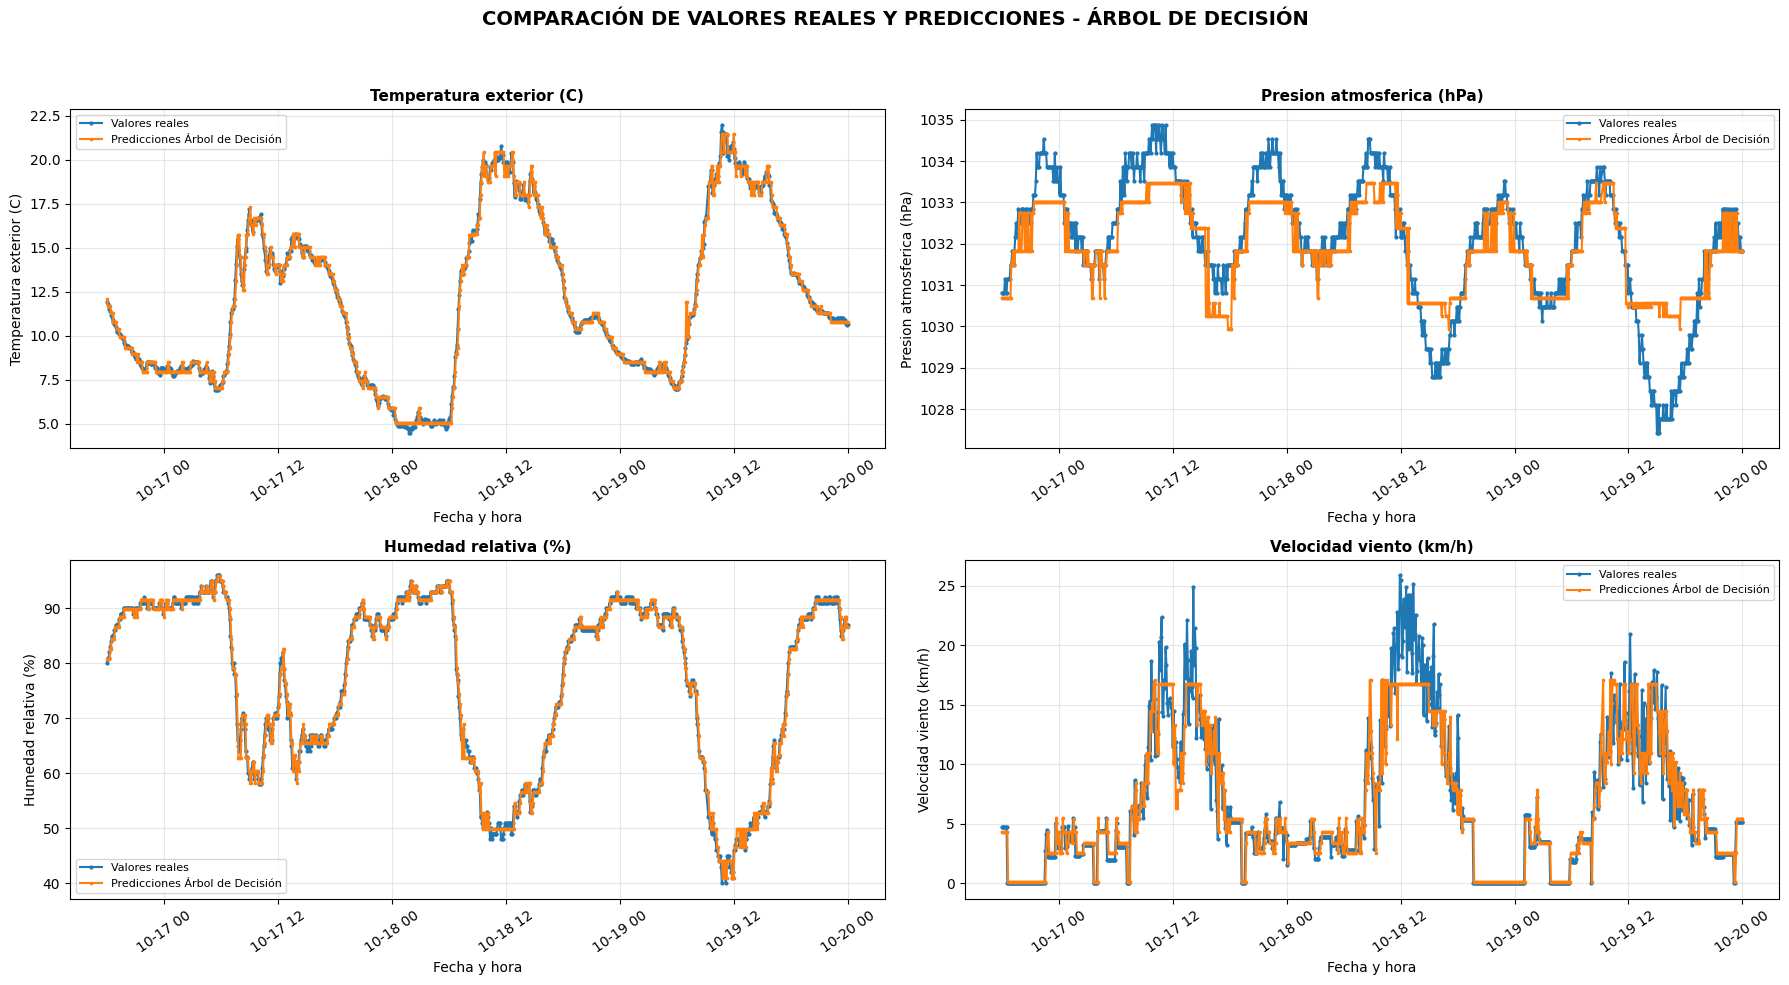


ENTRENAMIENTO ÁRBOL DE DECISIÓN FINALIZADO


In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error)

variables = [
    "Temperatura exterior (C)",
    "Presion atmosferica (hPa)",
    "Humedad relativa (%)",
    "Velocidad viento (km/h)"]

datos = df.copy()
datos["Fecha y hora"] = pd.to_datetime( datos["Local Date Time"],errors="coerce")
datos = datos.dropna(subset=["Fecha y hora"] + variables)
datos = datos.sort_values("Fecha y hora").reset_index(drop=True)
datos["hora"] = datos["Fecha y hora"].dt.hour
datos["dia"] = datos["Fecha y hora"].dt.dayofyear

datos["hora_sin"] = np.sin(2 * np.pi * datos["hora"] / 24)
datos["hora_cos"] = np.cos(2 * np.pi * datos["hora"] / 24)

datos["dia_sin"] = np.sin(2 * np.pi * datos["dia"] / 365)
datos["dia_cos"] = np.cos(2 * np.pi * datos["dia"] / 365)

for variable in variables:
    datos[variable + "_lag1"] = datos[variable].shift(1)
    datos[variable + "_lag2"] = datos[variable].shift(2)

datos = datos.dropna().reset_index(drop=True)

caracteristicas = []
for variable in variables:
    caracteristicas.append(variable + "_lag1")
    caracteristicas.append(variable + "_lag2")

caracteristicas += [
    "hora_sin",
    "hora_cos",
    "dia_sin",
    "dia_cos"]

X = datos[caracteristicas]
corte = int(len(datos) * 0.80)

X_train = X.iloc[:corte]
X_test = X.iloc[corte:]

fechas_test = datos["Fecha y hora"].iloc[corte:]

print("Registros para entrenamiento:", len(X_train))
print("Registros para prueba:", len(X_test))

resultados = []
modelos_entrenados = {}
predicciones = {}

for variable in variables:

    print("\nEntrenando Árbol de Decisión para:", variable)

    y = datos[variable]

    y_train = y.iloc[:corte]
    y_test = y.iloc[corte:]

    modelo = DecisionTreeRegressor(
        max_leaf_nodes=40,
        min_samples_split=2,
        min_samples_leaf=2,
        random_state=42 )

    modelo.fit(X_train, y_train)

    y_pred = modelo.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)

    promedio_real = np.mean(np.abs(y_test))

    if promedio_real != 0:
        ajuste = max(0, 100 * (1 - mae / promedio_real))
    else:
        ajuste = 0

    resultados.append({
        "Variable": variable,
        "R2": r2,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "Ajuste estimado (%)": ajuste})

    modelos_entrenados[variable] = modelo
    predicciones[variable] = y_pred

    print("R²:", round(r2, 4))
    print("MAE:", round(mae, 4))
    print("MSE:", round(mse, 4))
    print("RMSE:", round(rmse, 4))
    print("Ajuste estimado:", round(ajuste, 2), "%")

tabla_resultados = pd.DataFrame(resultados)

print("\nRESULTADOS GENERALES - ÁRBOL DE DECISIÓN")
display(tabla_resultados.round(4))

fig, ejes = plt.subplots(2, 2, figsize=(18, 10))
ejes = ejes.flatten()

for posicion, variable in enumerate(variables):

    ax = ejes[posicion]

    y_test = datos[variable].iloc[corte:]
    y_pred = predicciones[variable]

    ax.plot(
        fechas_test,
        y_test.values,
        label="Valores reales",
        marker="o",
        markersize=2,
        linewidth=1.5)

    ax.plot(
        fechas_test,
        y_pred,
        label="Predicciones Árbol de Decisión",
        marker="s",
        markersize=2,
        linewidth=1.5)

    ax.set_title(variable, fontsize=11, fontweight="bold")
    ax.set_xlabel("Fecha y hora")
    ax.set_ylabel(variable)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis="x", rotation=35)

fig.suptitle(
    "COMPARACIÓN DE VALORES REALES Y PREDICCIONES - ÁRBOL DE DECISIÓN",
    fontsize=14,
    fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

print("\nENTRENAMIENTO ÁRBOL DE DECISIÓN FINALIZADO")
